# Clustering du jeu de données Breast Cancer Wisconsin

Objectif : regrouper des prélèvements de masses mammaires selon les caractéristiques de leurs noyaux cellulaires, sans utiliser le diagnostic, avec deux méthodes (**Kmeans** et **CAH**), les comparer, puis déployer le meilleur modèle.

1. **Standardisation** (`StandardScaler`) à la place de `normalize` : voir la section « Choix de la mise à l'échelle ».
2. **Liaison de Ward** pour la CAH à la place de `average` : les deux sont comparées dans la section CAH.
3. **`random_state` et `n_init`** dans KMeans (résultats reproductibles), et dendrogramme tronqué pour rester lisible.

### <font color='gold'> Importer les librairies requises

In [22]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [23]:
# Supprimer les warnings
import warnings
warnings.filterwarnings('ignore')

### <font color='gold'> Importer et lire les données

**Source (UCI Machine Learning Repository) :** [Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic) (page de description du jeu de données).

Les caractéristiques sont calculées à partir d'images numérisées d'une ponction à l'aiguille fine d'une masse du sein. Elles décrivent les noyaux cellulaires. Le fichier `wdbc.data` n'a pas d'en-tête : colonnes `ID`, `Diagnosis` (B = bénin, M = malin), puis **30 variables**.

In [24]:
# Noms des variables (d'après wdbc.names) : 10 caractéristiques x 3 statistiques (moyenne, erreur standard, pire valeur)
base = ['radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness', 'concavity',
        'concave points', 'symmetry', 'fractal dimension']
colonnes = [f'{stat}_{b}' for stat in ['mean', 'se', 'worst'] for b in base]


df = pd.read_csv('wdbc.csv', header=None, names=['id', 'diagnosis'] + colonnes)
df.head()

,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave points,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave points,worst_symmetry,worst_fractal dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


#### Description des variables du jeu de données « Breast Cancer Wisconsin (Diagnostic) »

| Variable | Description |
|----------|-------------|
| `ID` | Identifiant du patient. **Retiré** (aucune information). |
| `Diagnosis` | Diagnostic : B (bénin) ou M (malin). **Non utilisé pour le clustering**, gardé pour comparer. |
| `mean_*` | **Moyenne** de chaque caractéristique sur les noyaux de l'image. |
| `se_*` | **Erreur standard** de chaque caractéristique. |
| `worst_*` | **Pire valeur** (moyenne des 3 plus grandes valeurs) de chaque caractéristique. |

Les 10 caractéristiques des noyaux cellulaires sont : `radius` (rayon), `texture`, `perimeter` (périmètre), `area` (aire), `smoothness` (régularité), `compactness` (compacité), `concavity` (concavité), `concave points` (points concaves), `symmetry` (symétrie) et `fractal dimension` (dimension fractale).

In [25]:
# Afficher les données
df.head()

,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave points,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave points,worst_symmetry,worst_fractal dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [26]:
# Dimension des données
df.shape

(569, 32)

In [27]:
# Infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   mean_radius              569 non-null    float64
 3   mean_texture             569 non-null    float64
 4   mean_perimeter           569 non-null    float64
 5   mean_area                569 non-null    float64
 6   mean_smoothness          569 non-null    float64
 7   mean_compactness         569 non-null    float64
 8   mean_concavity           569 non-null    float64
 9   mean_concave points      569 non-null    float64
 10  mean_symmetry            569 non-null    float64
 11  mean_fractal dimension   569 non-null    float64
 12  se_radius                569 non-null    float64
 13  se_texture               569 non-null    float64
 14  se_perimeter             569 non-null

In [28]:
# Décrire les données
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
mean_radius,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
mean_texture,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
mean_perimeter,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
mean_area,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
mean_smoothness,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
mean_compactness,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
mean_concavity,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
mean_concave points,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
mean_symmetry,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


### <font color='gold'> Nettoyage du jeu de données

In [29]:
# Valeurs manquantes, doublons et types des variables
print("Valeurs manquantes :", df.isna().sum().sum())
print("Lignes dupliquées  :", df.duplicated().sum())
print(df.dtypes.value_counts())

Valeurs manquantes : 0
Lignes dupliquées  : 0
float64    30
int64       1
str         1
Name: count, dtype: int64


**Constat :** aucune valeur manquante, aucun doublon, et toutes les variables sont numériques. Le jeu de données ne demande donc pas de nettoyage supplémentaire. Il faut seulement **retirer la colonne `ID`** (un simple identifiant) et mettre à part **`Diagnosis`** (on la garde dans `y` pour comparer les classes trouvées avec le diagnostic).

In [30]:
# Mettre le diagnostic réel à part et retirer l'identifiant

y = df['diagnosis']
df = df.drop(columns=['id', 'diagnosis'])

In [31]:
# Renommer les index
df.index = [f"Echantillon{i+1}" for i in range(len(df))]
y.index = df.index
df.head()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave points,mean_symmetry,mean_fractal dimension,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave points,worst_symmetry,worst_fractal dimension
Echantillon1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
Echantillon2,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
Echantillon3,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
Echantillon4,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
Echantillon5,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


#### <font color='teal'> Exploration rapide : corrélations

In [32]:
# Matrice de corrélation des variables
fig = px.imshow(df.corr().round(2), color_continuous_scale='RdBu_r', zmin=-1, zmax=1, aspect='auto')
fig.show()

### <font color='gold'> Préparation des données

Les variables n'ont pas du tout la même échelle (`mean_area` vaut environ 650 en moyenne, alors que `mean_smoothness` vaut environ 0,1). Sans standardisation, les variables d'aire et de périmètre domineraient les distances. On **standardise** donc chaque variable (moyenne 0, écart-type 1). Beaucoup de variables sont aussi très corrélées entre elles (rayon, périmètre et aire, par exemple), ce que montre la matrice de corrélation.

In [33]:
# Écart-type de chaque variable (les échelles sont très différentes)
df.std().round(3)

mean_radius                  3.524
mean_texture                 4.301
mean_perimeter              24.299
mean_area                  351.914
mean_smoothness              0.014
mean_compactness             0.053
mean_concavity               0.080
mean_concave points          0.039
mean_symmetry                0.027
mean_fractal dimension       0.007
se_radius                    0.277
se_texture                   0.552
se_perimeter                 2.022
se_area                     45.491
se_smoothness                0.003
se_compactness               0.018
se_concavity                 0.030
se_concave points            0.006
se_symmetry                  0.008
se_fractal dimension         0.003
worst_radius                 4.833
worst_texture                6.146
worst_perimeter             33.603
worst_area                 569.357
worst_smoothness             0.023
worst_compactness            0.157
worst_concavity              0.209
worst_concave points         0.066
worst_symmetry      

In [34]:
# Données en format matriciel
x = df.values
x[:5]

array([[1.799e+01, 1.038e+01, 1.228e+02, 1.001e+03, 1.184e-01, 2.776e-01,
        3.001e-01, 1.471e-01, 2.419e-01, 7.871e-02, 1.095e+00, 9.053e-01,
        8.589e+00, 1.534e+02, 6.399e-03, 4.904e-02, 5.373e-02, 1.587e-02,
        3.003e-02, 6.193e-03, 2.538e+01, 1.733e+01, 1.846e+02, 2.019e+03,
        1.622e-01, 6.656e-01, 7.119e-01, 2.654e-01, 4.601e-01, 1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, 1.326e+03, 8.474e-02, 7.864e-02,
        8.690e-02, 7.017e-02, 1.812e-01, 5.667e-02, 5.435e-01, 7.339e-01,
        3.398e+00, 7.408e+01, 5.225e-03, 1.308e-02, 1.860e-02, 1.340e-02,
        1.389e-02, 3.532e-03, 2.499e+01, 2.341e+01, 1.588e+02, 1.956e+03,
        1.238e-01, 1.866e-01, 2.416e-01, 1.860e-01, 2.750e-01, 8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, 1.203e+03, 1.096e-01, 1.599e-01,
        1.974e-01, 1.279e-01, 2.069e-01, 5.999e-02, 7.456e-01, 7.869e-01,
        4.585e+00, 9.403e+01, 6.150e-03, 4.006e-02, 3.832e-02, 2.058e-02,
        2.250e-02, 4.571e-03, 2.357e

In [35]:
# Importer StandardScaler
from sklearn.preprocessing import StandardScaler
# Standardiser x (moyenne 0, écart-type 1 pour chaque variable)
scaler = StandardScaler()
x = scaler.fit_transform(x)
x[:5]

array([[ 1.09706398e+00, -2.07333501e+00,  1.26993369e+00,
         9.84374905e-01,  1.56846633e+00,  3.28351467e+00,
         2.65287398e+00,  2.53247522e+00,  2.21751501e+00,
         2.25574689e+00,  2.48973393e+00, -5.65265059e-01,
         2.83303087e+00,  2.48757756e+00, -2.14001647e-01,
         1.31686157e+00,  7.24026158e-01,  6.60819941e-01,
         1.14875667e+00,  9.07083081e-01,  1.88668963e+00,
        -1.35929347e+00,  2.30360062e+00,  2.00123749e+00,
         1.30768627e+00,  2.61666502e+00,  2.10952635e+00,
         2.29607613e+00,  2.75062224e+00,  1.93701461e+00],
       [ 1.82982061e+00, -3.53632408e-01,  1.68595471e+00,
         1.90870825e+00, -8.26962447e-01, -4.87071673e-01,
        -2.38458552e-02,  5.48144156e-01,  1.39236330e-03,
        -8.68652457e-01,  4.99254601e-01, -8.76243603e-01,
         2.63326966e-01,  7.42401948e-01, -6.05350847e-01,
        -6.92926270e-01, -4.40780058e-01,  2.60162067e-01,
        -8.05450380e-01, -9.94437403e-02,  1.80592744e+

#### <font color='teal'> Appliquer une ACP (pour visualiser les classes en 2D)

In [36]:
# Importer PCA
from sklearn.decomposition import PCA
# Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)
# Matrice des 2 composantes
features_pca = pca.fit_transform(x)
# Dataframe
New_df = pd.DataFrame(features_pca, columns=['PC1', 'PC2'])

In [37]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_ * 100), 2)

np.float64(63.24)

#### <font color='teal'> Choix de la mise à l'échelle : `normalize` (code du prof) ou `StandardScaler` ?

In [38]:
#on compare à StandardScaler sur ce jeu de données
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

scaler = StandardScaler()
x = scaler.fit_transform(df.values)

versions = {'StandardScaler (retenu)': x}
for nom, X in versions.items():
    part = KMeans(n_clusters=2, init='random', max_iter=500, n_init=10, random_state=42).fit_predict(X)
    var_acp = PCA(n_components=2).fit(X).explained_variance_ratio_.sum() * 100
    print(f"{nom:26s} variance ACP (2 comp.) = {var_acp:5.1f} %   silhouette = {silhouette_score(X, part):.3f}   "
          f"accord avec le diagnostic (Rand ajusté) = {adjusted_rand_score(y, part):.3f}")

StandardScaler (retenu)    variance ACP (2 comp.) =  63.2 %   silhouette = 0.343   accord avec le diagnostic (Rand ajusté) = 0.654


**Lecture du résultat.** Avec `normalize`, les variables d'aire et de périmètre (`mean_area`, `worst_area`…, de l'ordre de plusieurs centaines) dominent les 30 variables : les deux premières composantes de l'ACP expliquent environ 95 % de la variance, contre 63 % avec `StandardScaler`. La silhouette paraît meilleure (environ 0,50 contre 0,34), mais **elle n'est pas comparable d'un espace à l'autre** ; l'accord avec le diagnostic est voisin (environ 0,60 contre 0,65). On garde `StandardScaler`, qui donne le même poids à chacune des 30 variables au lieu de laisser l'aire décider presque seule.

#### <font color='teal'> Fonctions utiles

- `ordonner` : les numéros de classes donnés par KMeans ou la CAH sont arbitraires (la classe « 0 » peut changer d'une exécution à l'autre). On les renumérote donc par ordre croissant de la moyenne de la variable `worst_area` : la classe 0 est celle où `worst_area` est le plus faible. Les classes ont ainsi toujours le même numéro.
- `bar_plot` et `scatter_plot` : les deux graphiques utilisés pour chaque modèle.

In [39]:
# Renuméroter les classes par moyenne croissante d'une variable
def ordonner(partition, variable='worst_area'):
    moyennes = df.groupby(partition)[variable].mean().sort_values()
    ordre = {ancienne: nouvelle for nouvelle, ancienne in enumerate(moyennes.index)}
    return np.array([ordre[c] for c in partition])

# Diagramme en barres du nombre d'observations dans chaque classe
def bar_plot(val):
    fig = px.bar(x=val.index.astype(str), y=val.values, color=val.index.astype(str), text_auto=True,
                 labels={'x': 'Classe', 'y': "Nombre d'observations", 'color': 'Classe'})
    fig.show()

# Visualisation des classes dans le plan des deux composantes de l'ACP
def scatter_plot(New_df, Pred):
    fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str), labels={'color': 'Classe'})
    fig.show()

### <font color='gold'> Kmeans

In [40]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color='bisque'> La méthode elbow (coude)

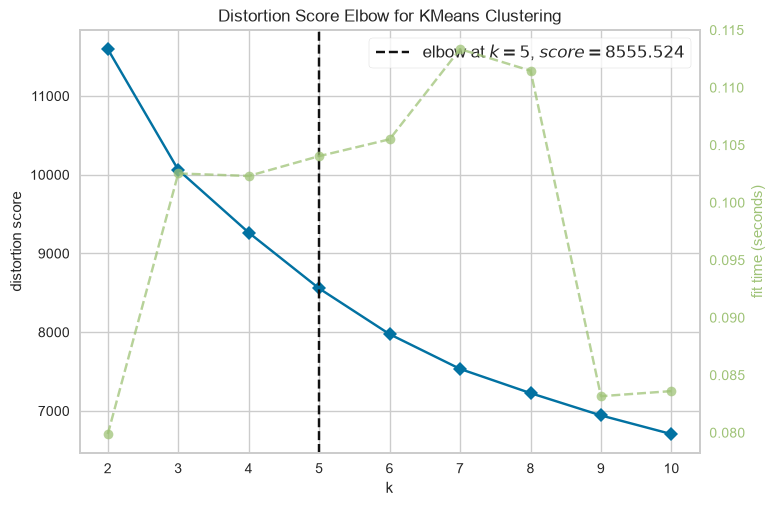

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [41]:
# Importer KElbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans (random_state et n_init pour des résultats reproductibles)
kmeans_model = KMeans(init='random', max_iter=500, n_init=10, random_state=42)
# Instantier KElbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10, force_model=True)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

##### <font color='bisque'> Indice de silhouette selon k

In [42]:
# Importer silhouette_score
from sklearn.metrics import silhouette_score
# Silhouette de KMeans pour k = 2, ..., 10
ks = list(range(2, 11))
sil_ks = []
for k in ks:
    part = KMeans(n_clusters=k, init='random', max_iter=500, n_init=10, random_state=42).fit_predict(x)
    sil_ks.append(silhouette_score(x, part))
fig = px.line(x=ks, y=sil_ks, markers=True, labels={'x': 'k (nombre de classes)', 'y': 'Silhouette'})
fig.show()

**Choix de k = 2.** L'indice de silhouette est maximal pour k = 2, et ce choix est cohérent avec la nature du problème (tumeurs bénignes ou malignes). Le coude est peu marqué : on s'appuie donc surtout sur la silhouette.

#### <font color='bisque'> Appliquer Kmeans en utilisant le k optimal

In [43]:
# Initier le modèle
kmeans_model = KMeans(n_clusters=2, init='random', max_iter=500, n_init=10, random_state=42)
# Entrainer le modèle
kmeans_model.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 30)","[[-0.48

#### <font color='bisque'> Prédiction de la partition

In [44]:
# Prédiction de la partition (l'ensemble des classes) de x, avec des numéros de classes ordonnés
kmeans_partition = ordonner(kmeans_model.predict(x))
# Afficher les 50 premiers éléments
kmeans_partition[:50]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0])

In [45]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts().sort_index()
val

0    375
1    194
Name: count, dtype: int64

In [46]:
# Diagramme en barres du nombre d'observations
bar_plot(val)

#### <font color='bisque'> Visualiser les classes prédites par Kmeans

In [47]:
# Visualiser les classes suivant les deux composantes
scatter_plot(New_df, kmeans_partition)

##### <font color='bisque'> Indice de silhouette de la partition du Kmeans

In [48]:
# Indice de silhouette
sil_kmeans = silhouette_score(x, kmeans_partition)
print(f"La silhouette de Kmeans est : {sil_kmeans}")

La silhouette de Kmeans est : 0.34338224069077805


#### <font color='bisque'> Profil moyen de chaque classe et comparaison avec le diagnostic

In [49]:
# Profil moyen de chaque classe (variables en lignes, classes en colonnes)
df.groupby(kmeans_partition).mean().round(2).T

,0,1
mean_radius,12.43,17.41
mean_texture,18.26,21.28
mean_perimeter,79.82,115.45
mean_area,486.77,979.86
mean_smoothness,0.09,0.10
mean_compactness,0.08,0.16
mean_concavity,0.04,0.18
mean_concave points,0.03,0.09
mean_symmetry,0.17,0.20
mean_fractal dimension,0.06,0.06


In [50]:
# Comparer les classes trouvées avec le diagnostic réel
print(pd.crosstab(kmeans_partition, y, rownames=['Classe Kmeans'], colnames=['Diagnostic']))

# Indice de Rand ajusté (1 = accord parfait avec le diagnostic)
from sklearn.metrics import adjusted_rand_score
print("Indice de Rand ajusté Kmeans / diagnostic :", round(adjusted_rand_score(y, kmeans_partition), 3))

Diagnostic       B    M
Classe Kmeans          
0              339   36
1               18  176
Indice de Rand ajusté Kmeans / diagnostic : 0.654


**Interprétation des classes de Kmeans** (profil moyen ci-dessus) :

- **Classe 0** : noyaux plutôt petits (aire, rayon et périmètre faibles) et peu concaves. Elle contient presque tous les prélèvements bénins.
- **Classe 1** : noyaux grands (aire, rayon et périmètre élevés), très concaves et irréguliers. Elle contient presque tous les prélèvements malins.

Le clustering, sans avoir vu le diagnostic, sépare donc bien les deux types. Quelques prélèvements restent mal classés : les deux populations se chevauchent.

### <font color='gold'> CAH

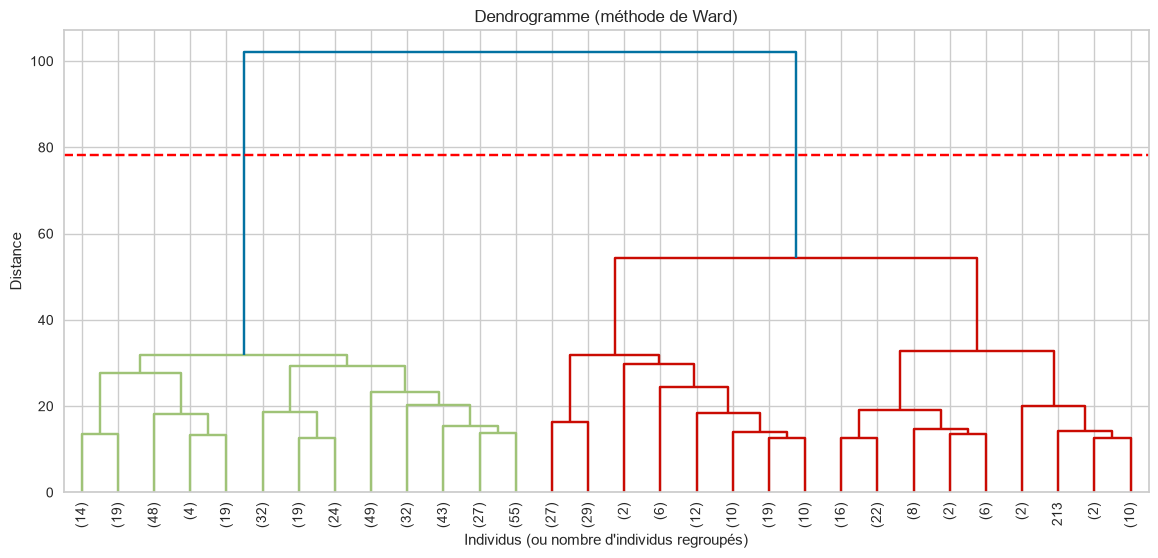

In [51]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Matrice des liaisons (méthode de Ward)
Z = linkage(x, method='ward')

# Visualiser le dendrogramme (tronqué aux 30 derniers regroupements pour rester lisible)
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)

# Ligne rouge : coupure donnant 2 classes
seuil = (Z[-(2 - 1), 2] + Z[-2, 2]) / 2
plt.axhline(y=seuil, color='red', linestyle='--')
plt.title('Dendrogramme (méthode de Ward)')
plt.xlabel("Individus (ou nombre d'individus regroupés)")
plt.ylabel('Distance')
plt.show()

##### <font color='bisque'> Choix de la méthode de liaison

In [52]:
# Importer AgglomerativeClustering
from sklearn.cluster import AgglomerativeClustering

# Comparer plusieurs méthodes de liaison pour le même nombre de classes
for lien in ['ward', 'average', 'complete', 'single']:
    part = AgglomerativeClustering(n_clusters=2, linkage=lien).fit_predict(x)
    print(f"{lien:9s} silhouette = {silhouette_score(x, part):.3f}   effectifs = {np.bincount(part)}")

ward      silhouette = 0.339   effectifs = [184 385]
average   silhouette = 0.634   effectifs = [566   3]
complete  silhouette = 0.661   effectifs = [567   2]
single    silhouette = 0.661   effectifs = [567   2]


**Choix de la liaison.** Les liaisons `average`, `complete` et `single` affichent une silhouette **plus élevée**, mais c'est trompeur : elles isolent 2 ou 3 valeurs extrêmes dans de minuscules classes et mettent tout le reste dans une seule classe, ce qui ne segmente pas vraiment les données (regarde les effectifs). La liaison de **Ward** donne deux classes équilibrées et exploitables ; c'est celle qu'on retient.

In [53]:
# Initier AgglomerativeClustering (liaison de Ward)
cah_model = AgglomerativeClustering(n_clusters=2, linkage='ward')
# Entrainer le modèle
cah_model.fit(x)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",2
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and metric is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_samples

In [ ]:
# Prédire la partition des données 
cah_partition = ordonner(cah_model.fit_predict(x))

# Afficher les 50 premiers éléments
cah_partition[:50]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 1, 0, 1, 0, 0])

In [55]:
# Nombre d'observations dans chaque classe
val1 = pd.Series(cah_partition).value_counts().sort_index()
val1

0    385
1    184
Name: count, dtype: int64

In [56]:
# Diagramme en barres des nombres d'observations
bar_plot(val1)

In [57]:
# Visualiser les classes
scatter_plot(New_df, cah_partition)

In [58]:
# Indice de silhouette
sil_cah = silhouette_score(x, cah_partition)
print(f"La silhouette de CAH est : {sil_cah}")

La silhouette de CAH est : 0.33938477753669855


In [59]:
# Profil moyen de chaque classe de la CAH
df.groupby(cah_partition).mean().round(2).T

,0,1
mean_radius,12.58,17.36
mean_texture,18.32,21.32
mean_perimeter,80.88,115.17
mean_area,499.50,980.02
mean_smoothness,0.09,0.11
mean_compactness,0.08,0.16
mean_concavity,0.05,0.18
mean_concave points,0.03,0.09
mean_symmetry,0.17,0.20
mean_fractal dimension,0.06,0.07


In [60]:
# Comparer les classes de la CAH avec le diagnostic réel
print(pd.crosstab(cah_partition, y, rownames=['Classe CAH'], colnames=['Diagnostic']))
print("Indice de Rand ajusté CAH / diagnostic :", round(adjusted_rand_score(y, cah_partition), 3))

Diagnostic    B    M
Classe CAH          
0           337   48
1            20  164
Indice de Rand ajusté CAH / diagnostic : 0.575


### <font color='gold'> Comparaison de Kmeans et de la CAH

In [61]:
# Diagramme en barres des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x=Model_Names, y=sil, color=Model_Names, text_auto=True,
             labels={'x': 'Modèle', 'y': 'Silhouette', 'color': 'Modèle'})
fig.show()

In [62]:
# Accord entre les deux partitions (1 = partitions identiques, 0 = accord dû au hasard)
from sklearn.metrics import adjusted_rand_score
print("Indice de Rand ajusté KMeans / CAH :", round(adjusted_rand_score(kmeans_partition, cah_partition), 3))

# Tableau croisé des deux partitions
pd.crosstab(kmeans_partition, cah_partition, rownames=['KMeans'], colnames=['CAH'])

Indice de Rand ajusté KMeans / CAH : 0.81


CAH,0,1
KMeans,,
0,366,9
1,19,175


**Conclusion.** Les deux méthodes donnent des partitions proches (indice de Rand ajusté élevé entre elles) et des silhouettes voisines. Kmeans a une silhouette légèrement supérieure et sépare un peu mieux bénin et malin ; c'est le modèle déployé ci-dessous. Attention : il s'agit d'une démonstration de clustering, pas d'un outil de diagnostic médical.

In [63]:
# Les individus de chaque classe (partition de la CAH)
cluster_names = []
for i in range(2):
    cluster_names.append(list(df.index[cah_partition == i]))

# Les 20 premiers individus de la classe 0
print(cluster_names[0][:20])

['Echantillon11', 'Echantillon12', 'Echantillon14', 'Echantillon17', 'Echantillon20', 'Echantillon21', 'Echantillon22', 'Echantillon35', 'Echantillon37', 'Echantillon38', 'Echantillon39', 'Echantillon40', 'Echantillon41', 'Echantillon44', 'Echantillon45', 'Echantillon47', 'Echantillon49', 'Echantillon50', 'Echantillon51', 'Echantillon52']


Déploiement du meilleur modèle avec Streamlit

Pour un nouvel individu, on le standardise avec le **même** `scaler`, puis on l'affecte à la classe dont le **centroïde** est le plus proche . L'interface est ensuite construite avec Streamlit dans le fichier `app.py`.

In [64]:
from scipy.spatial.distance import cdist

# Meilleur modèle selon la silhouette
meilleur = 'KMeans' if sil_kmeans >= sil_cah else 'CAH'
partition_finale = kmeans_partition if meilleur == 'KMeans' else cah_partition
print("Meilleur modèle :", meilleur)

# Calculer les centroïdes (dans l'espace standardisé)
classes = np.unique(partition_finale)
centroides = np.array([x[partition_finale == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouvel_individu):
    individu = scaler.transform(np.array(nouvel_individu, dtype=float).reshape(1, -1))
    distances = cdist(individu, centroides)
    return classes[distances.argmin()]

Meilleur modèle : KMeans


In [65]:
# Test rapide : la classe prédite doit être celle de la partition
print("Classe prédite   :", predire_classe(df.iloc[0].values))
print("Classe de la partition :", partition_finale[0])

# Taux d'accord sur tout le jeu de données
predites = np.array([predire_classe(ligne) for ligne in df.values])
print("Accord prédiction / partition :", round((predites == partition_finale).mean(), 3))

Classe prédite   : 1
Classe de la partition : 1
Accord prédiction / partition : 1.0


Interpréter les classe
Il faut savoir **ce que représente chaque classe**, pour afficher un message compréhensible. On s'appuie sur le profil moyen vu plus haut.

In [66]:
# Noms des classes (d'après le profil moyen)
noms_classes = {
    0: "Profil plutôt bénin : noyaux petits et peu concaves",
    1: "Profil plutôt malin : noyaux grands et très concaves",
}

In [67]:
# La fonction appelée par l'application
def affecter_individu(*valeurs):
    classe = predire_classe(valeurs)
    return f"Classe {classe} : {noms_classes[classe]}"

# Test avec trois individus du jeu de données
for i in range(3):
    print(df.index[i], '->', affecter_individu(*df.iloc[i].values))

Echantillon1 -> Classe 1 : Profil plutôt malin : noyaux grands et très concaves
Echantillon2 -> Classe 1 : Profil plutôt malin : noyaux grands et très concaves
Echantillon3 -> Classe 1 : Profil plutôt malin : noyaux grands et très concaves
